<a href="https://colab.research.google.com/github/RainanCoelho/Projeto-Analise-Exploratoria-Grupo8-Gestao_de_Vendedores-Parceiros/blob/main/Dataset_order_reviews_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import pandas as pd
import numpy as np

URL = "https://raw.githubusercontent.com/RainanCoelho/Projeto-Analise-Exploratoria-Grupo8-Gestao_de_Vendedores-Parceiros/refs/heads/main/olist_order_reviews_dataset.csv"
df_ord = pd.read_csv(URL)
df_ord.columns = ["review_id","order_id","review_score","review_comment_title","review_comment_message","review_creation_date","review_answer_timestamp"]
df_ord.head(5)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


PARTE 1: CONHECIMENTO DOS DADOS

In [ ]:
df_ord.shape #Mostra no console a quantidade de linhas e colunas do dataset

(99224, 7)

In [ ]:
df_ord.info() #Mostra o tipo e a quantidade de valores não nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [ ]:
df_ord.describe() #Mostra a estatística das tabelas, como média, valor máximo, mínimo, valores interquartis e mais

,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


In [ ]:
df_ord.dtypes #Mostra os tipos de cada coluna

,0
review_id,object
order_id,object
review_score,int64
review_comment_title,object
review_comment_message,object
review_creation_date,object
review_answer_timestamp,object


PARTE 2: CORREÇÃO DE TIPOS

In [33]:
def correção_de_tipo_date(df):
  df = df.copy()
  tipos_date = ["review_creation_date","review_answer_timestamp"]
  for coluna in tipos_date:
    df[coluna] = pd.to_datetime(df[coluna], errors="coerce")
  return df

df_ord = correção_de_tipo_date(df_ord)
df_ord.dtypes

,0
review_id,object
order_id,object
review_score,int64
review_comment_title,object
review_comment_message,object
review_creation_date,datetime64[ns]
review_answer_timestamp,datetime64[ns]


PARTE 3: VERIFICAÇÃO DE VALORES

In [ ]:
df_ord.isnull().sum() #Verifica quantos valores nulos existem em cada coluna

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


**Explicação**: Os valores onde foram registrados como nulo foram apenas nas colunas atreladas a comentários, algo que normalmente não é considerado obrigatório, então os valores nulos na coluna não são tão perigosos e errados assim

In [ ]:
df_ord.duplicated().sum() #Verificar se tem linhas da tabela duplicadas

np.int64(0)

**Explicação**: Já que não houve linhas duplicadas não se faz nada

In [ ]:
df_ord["review_id"].duplicated().sum()

np.int64(814)

In [ ]:
df_ord["review_id"].isnull().sum()

np.int64(0)

In [ ]:
df_ord["order_id"].duplicated().sum()

np.int64(551)

In [ ]:
df_ord["order_id"].isnull().sum()

np.int64(0)

**Explicação**: Não foi visto nenhum valor de ID nulo, porém, no há um valor grande de duplicadas de cada ID, porém, não tem motivos de excluir nada, já que são valores normais, ter mais de um "review_id" apenas confirma que o mesmo número de pesquisa aparece em mais de um pedido, ou seja, ele fez dois pedidos, mas deu uma nota, e isso conta para os dois, e ter mais de um "order_id" indica que o mesmo pedido aparece com mais de uma pesquisa, tipo o cliente dar mais de uma review para o mesmo pedido

In [ ]:
print("Acima: ", (df_ord["review_creation_date"].dt.year > 2018).sum()) #Conta quantos valores estão acima de 2018 na tebela
print("Abaixo: ", (df_ord["review_creation_date"].dt.year < 2016).sum()) #Conta quantos valores estão abaixo de 2016 na tabela

Acima:  0
Abaixo:  0


In [ ]:
print("Acima: ", (df_ord["review_answer_timestamp"].dt.year > 2018).sum()) #Conta quantos valores estão acima de 2018 na tebela
print("Abaixo: ", (df_ord["review_answer_timestamp"].dt.year < 2016).sum()) #Conta quantos valores estão abaixo de 2016 na tabela

Acima:  0
Abaixo:  0


In [ ]:
inconsistentes = df_ord[df_ord['review_creation_date'] > df_ord['review_answer_timestamp']]

print(len(inconsistentes))   # quantas são as linhas inconsistentes

0


**Explicação**: Verificar quantas são as linhas que possuem a data de criação depois da data de resposta da review, para ver se tem inconsistência, o valor foi 0, então não houve nenhuma

In [ ]:
print("Valor máximo: ",df_ord["review_score"].max()) #Verificar qual o valor máximo que uma nota chega
print("Valor mínimo: ",df_ord["review_score"].min()) #Verificar qual o valor mínimo que uma nota chega
print("Abaixo de 1: ",(df_ord["review_score"] < 1).sum()) #Verificar se tem reviews com notas abaixo de 0

Valor máximo:  5
Valor mínimo:  1
Abaixo de 1:  0


**Explicação**: Com a verificação do maior e menor valor de review's, se foi possível ver se existia algum valor abaixo de 1, sendo ela possívelmente uma suposta menor nota, foi vista que nenhuma nota foi menor que 1, então ela está boa

**Explicação**: Não vai haver outlier, já que não há valores numéricos de possibilidade teoricamente infinitas, apenas um valor já pré-montado com limite de 1 a 5, por isso, essa parte não irá ocorrer nesse dataset

**Explicação:** Não haverá uma padronização de textos de reviews, já que elas não são padronizadas, ou seja, podem ser textos longos, curtos, com diferentes mensagens e mais, e caso tenha algum texto com letras maiúsculas, também não mudará, pois isso pode expressar um setimento do cliente

**FRENTE 2**

PARTE 4: CRIAÇÃO DE NOVOS ATRIBUTOS (FEATURE ENGINEERING)

In [ ]:
def criar_features_reviews(df):
    out = df.copy()

    # Agrupa as notas de 1 a 5 em faixas de avaliação
    out["faixa_avaliacao"] = pd.cut(
        out["review_score"],
        bins=[0, 2, 3, 5],
        labels=["negativa", "neutra", "positiva"],
    )

    # Flag binária (1/0) para identificar avaliações negativas (notas 1 ou 2)
    out["flag_avaliacao_negativa"] = (out["review_score"] <= 2).astype(int)

    # Flag binária (1/0) indicando se o cliente deixou comentário escrito
    out["flag_tem_comentario"] = out["review_comment_message"].notna().astype(int)

    return out


# Gera o novo DataFrame com as features criadas
df_ord_f2 = criar_features_reviews(df_ord)

novas_cols = ["faixa_avaliacao", "flag_avaliacao_negativa", "flag_tem_comentario"]

# Exibe a contagem das faixas, estatísticas e nulos das novas colunas
print("Contagem por faixa de avaliação:")
print(df_ord_f2["faixa_avaliacao"].value_counts())
print("\nResumo estatístico:")
print(df_ord_f2[["flag_avaliacao_negativa", "flag_tem_comentario"]].describe())
print("\nNulos nas novas colunas:")
print(df_ord_f2[novas_cols].isna().sum())

Contagem por faixa de avaliação:
faixa_avaliacao
positiva    76470
negativa    14575
neutra       8179
Name: count, dtype: int64

Resumo estatístico:
       flag_avaliacao_negativa  flag_tem_comentario
count             99224.000000         99224.000000
mean                  0.146890             0.412975
std                   0.353998             0.492371
min                   0.000000             0.000000
25%                   0.000000             0.000000
50%                   0.000000             0.000000
75%                   0.000000             1.000000
max                   1.000000             1.000000

Nulos nas novas colunas:
faixa_avaliacao            0
flag_avaliacao_negativa    0
flag_tem_comentario        0
dtype: int64


**EXPLICAÇÃO**: A partir das notas de 1 a 5 já verificadas na tabela, foram criadas três colunas novas para facilitar o cruzamento das avaliações com os vendedores. As notas foram divididas em três faixas, onde 76.470 avaliações são positivas, 14.575 são negativas e 8.179 são neutras. Também foi visto que cerca de 14,7% das avaliações são negativas e que cerca de 41,3% dos pedidos têm comentário escrito, sem nenhum valor nulo nessas colunas novas.

PARTE 5: CODIFICAÇÃO DE DADOS CATEGÓRICOS

In [ ]:
def codificar_reviews(df):
    out = df.copy()

    # Transforma as faixas de avaliação em colunas binárias (0 e 1) mantendo a coluna original
    dummies = pd.get_dummies(out["faixa_avaliacao"], prefix="avaliacao", dtype=int)
    out = pd.concat([out, dummies], axis=1)

    return out


# Guarda as colunas anteriores para listar apenas as novas geradas
cols_originais = set(df_ord_f2.columns)

# Aplica a codificação e atualiza df_ord_f2
df_ord_f2 = codificar_reviews(df_ord_f2)

novas_cols = [col for col in df_ord_f2.columns if col not in cols_originais]

# Exibe as novas colunas, os totais de cada uma e as primeiras linhas
print("Novas colunas:", novas_cols)
print("\nTotais por coluna:")
print(df_ord_f2[novas_cols].sum())
print("\nPrimeiras linhas:")
print(df_ord_f2[novas_cols].head())

Novas colunas: ['avaliacao_negativa', 'avaliacao_neutra', 'avaliacao_positiva']

Totais por coluna:
avaliacao_negativa    14575
avaliacao_neutra       8179
avaliacao_positiva    76470
dtype: int64

Primeiras linhas:
   avaliacao_negativa  avaliacao_neutra  avaliacao_positiva
0                   0                 0                   1
1                   0                 0                   1
2                   0                 0                   1
3                   0                 0                   1
4                   0                 0                   1


**EXPLICAÇÃO**: Nesta etapa, a faixa de avaliação foi transformada em três colunas numéricas de 0 e 1, mantendo review_id e order_id intactos para juntar com a tabela de pedidos e vendedores depois. A coluna faixa_avaliacao original também foi mantida para facilitar filtros no painel, e os totais confirmaram 14.575 avaliações negativas, 8.179 neutras e 76.470 positivas.

PARTE 6: NORMALIZAÇÃO E PADRONIZAÇÃO

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler


def escalonar_reviews(df, colunas):
    out = df.copy()

    # Garante formato numérico e evita valores infinitos
    dados_num = out[colunas].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)

    minmax_scaler = MinMaxScaler()
    standard_scaler = StandardScaler()

    minmax_vals = minmax_scaler.fit_transform(dados_num)
    zscore_vals = standard_scaler.fit_transform(dados_num)

    # Atribui coluna por coluna mantendo a coluna original intacta
    for i, col in enumerate(colunas):
        out[f"{col}_minmax"] = minmax_vals[:, i]
        out[f"{col}_zscore"] = zscore_vals[:, i]

    return out


cols_escalar = ["review_score"]
df_ord_f2 = escalonar_reviews(df_ord_f2, cols_escalar)

cols_escalonadas = ["review_score_minmax", "review_score_zscore"]
print(df_ord_f2[cols_escalonadas].describe())

       review_score_minmax  review_score_zscore
count         99224.000000         9.922400e+04
mean              0.771605         2.112494e-16
std               0.336895         1.000005e+00
min               0.000000        -2.290356e+00
25%               0.750000        -6.413060e-02
50%               1.000000         6.779446e-01
75%               1.000000         6.779446e-01
max               1.000000         6.779446e-01


**EXPLICAÇÃO**: A nota da avaliação foi colocada nas escalas MinMax, entre 0 e 1, e Z-score, com média 0 e desvio padrão 1, criando duas colunas novas e mantendo a nota original de 1 a 5 para facilitar a leitura das regras. Todos os 99.224 registros permaneceram válidos, com a menor nota equivalente a cerca de 2,29 desvios abaixo da média e a maior nota a 0,68 desvio acima.

PARTE 7: SELEÇÃO DE ATRIBUTOS

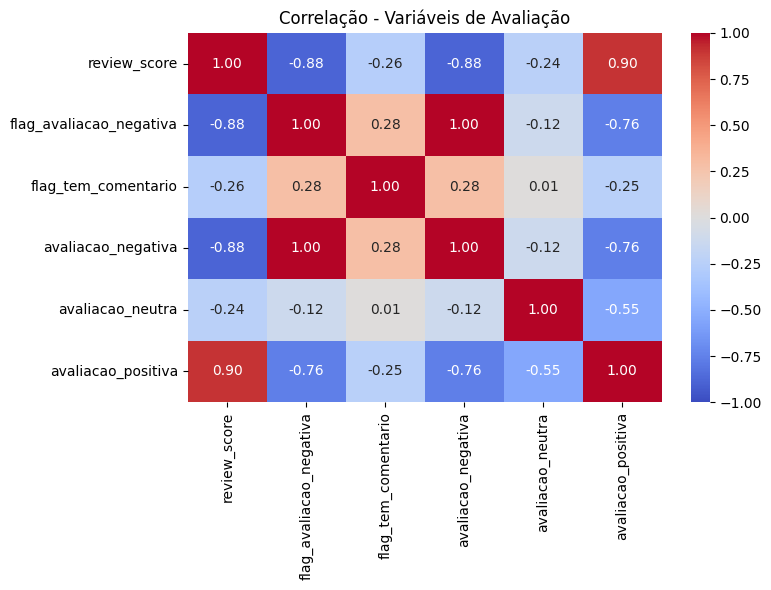

Colunas com variância <= 0.01: []
Shape antes: (99224, 15)
Shape depois: (99224, 12)
Colunas finais: ['review_id', 'order_id', 'review_score', 'review_creation_date', 'review_answer_timestamp', 'faixa_avaliacao', 'flag_avaliacao_negativa', 'flag_tem_comentario', 'avaliacao_neutra', 'avaliacao_positiva', 'review_score_minmax', 'review_score_zscore']


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold

cols_num = [
    "review_score",
    "flag_avaliacao_negativa",
    "flag_tem_comentario",
    "avaliacao_negativa",
    "avaliacao_neutra",
    "avaliacao_positiva",
]

# 1. Heatmap de correlação das variáveis numéricas (sem as escalonadas)
plt.figure(figsize=(8, 6))
sns.heatmap(df_ord_f2[cols_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação - Variáveis de Avaliação")
plt.tight_layout()
plt.show()

# 2. Verifica se há colunas com variância muito baixa (<= 0.01)
vt = VarianceThreshold(threshold=0.01)
vt.fit(df_ord_f2[cols_num])

baixa_variancia = [col for col, keep in zip(cols_num, vt.get_support()) if not keep]
print("Colunas com variância <= 0.01:", baixa_variancia)


# 3. Remove coluna redundante (1.00 com flag_avaliacao_negativa) e textos longos
def selecionar_atributos_reviews(df, cols_remover=None):
    out = df.copy()
    if cols_remover is None:
        cols_remover = ["avaliacao_negativa", "review_comment_title", "review_comment_message"]
    return out.drop(columns=cols_remover, errors="ignore")


print("Shape antes:", df_ord_f2.shape)
df_ord_sel = selecionar_atributos_reviews(df_ord_f2)
print("Shape depois:", df_ord_sel.shape)
print("Colunas finais:", list(df_ord_sel.columns))

**EXPLICAÇÃO**: O gráfico de calor mostrou que avaliacao_negativa era totalmente repetida com flag_avaliacao_negativa, e também mostrou uma ligação positiva entre avaliações ruins e a presença de comentários. O teste de variação confirmou que nenhuma das colunas numéricas tem variação baixa demais. Por fim, avaliacao_negativa e os textos longos de título e mensagem foram removidos, deixando a tabela mais leve, de 15 para 12 colunas, com todas as 99.224 avaliações prontas para o cruzamento com os vendedores.